##**NYC Yellow Taxi Data Analysis**


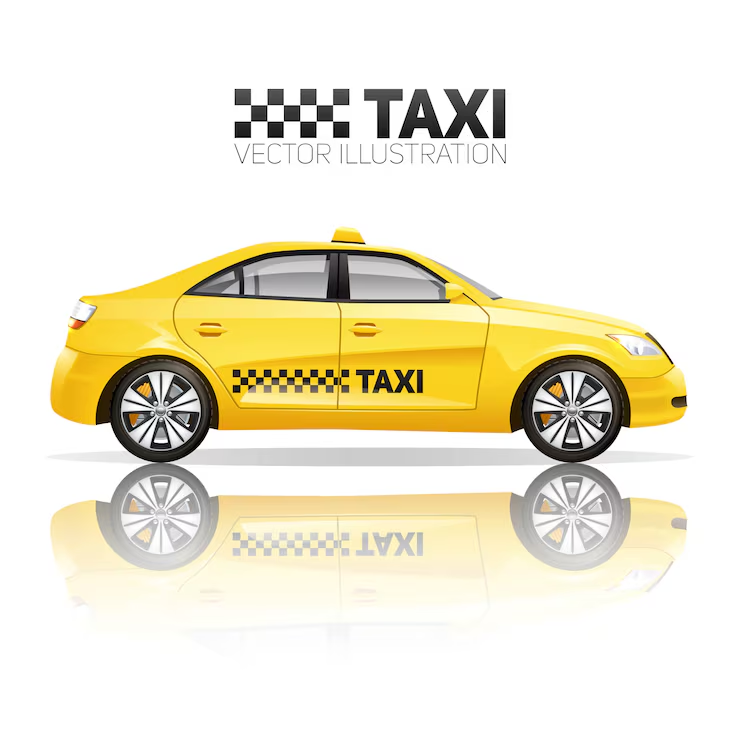

#problem statement

The project aims to analyze NYC Yellow Taxi trip records to understand trip patterns and operational characteristics. The analysis focuses on trip distance, duration, passenger count, time-based demand, pickup and drop-off locations, routes, payment types, vendors, and rate codes. It also identifies data-quality issues and unusual records and uses statistical analysis and visualizations to generate meaningful, evidence-based insights.

#project objective

1. To analyze NYC Yellow Taxi trip data for January 2025.

2. To perform data cleaning and quality assessment.

3. To analyze trip distance, duration, passenger count and time-based patterns.

4. To study pickup/drop-off locations, routes, payment types, vendors and rate codes.

5. To generate meaningful visualizations and evidence-based business insights from the dataset.

## 1. Import Libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


## 2. Load Dataset

In [ ]:
df = pd.read_parquet('/content/yellow_tripdata_2025-01 (3).parquet')
df

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
0,1,2025-01-01 00:18:38,2025-01-01 00:26:59,1.0,1.60,1.0,N,229,237,1,10.00,3.5,0.5,3.00,0.0,1.0,18.00,2.5,0.0,0.00
1,1,2025-01-01 00:32:40,2025-01-01 00:35:13,1.0,0.50,1.0,N,236,237,1,5.10,3.5,0.5,2.02,0.0,1.0,12.12,2.5,0.0,0.00
2,1,2025-01-01 00:44:04,2025-01-01 00:46:01,1.0,0.60,1.0,N,141,141,1,5.10,3.5,0.5,2.00,0.0,1.0,12.10,2.5,0.0,0.00
3,2,2025-01-01 00:14:27,2025-01-01 00:20:01,3.0,0.52,1.0,N,244,244,2,7.20,1.0,0.5,0.00,0.0,1.0,9.70,0.0,0.0,0.00
4,2,2025-01-01 00:21:34,2025-01-01 00:25:06,3.0,0.66,1.0,N,244,116,2,5.80,1.0,0.5,0.00,0.0,1.0,8.30,0.0,0.0,0.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3475221,2,2025-01-31 23:01:48,2025-01-31 23:16:29,NaN,3.35,NaN,None,79,237,0,15.85,0.0,0.5,0.00,0.0,1.0,20.60,NaN,NaN,0.75
3475222,2,2025-01-31 23:50:29,2025-02-01 00:17:27,NaN,8.73,NaN,None,161,116,0,28.14,0.0,0.5,0.00,0.0,1.0,32.89,NaN,NaN,0.75
3475223,2,2025-01-31 23:26:59,2025-01-31 23:43:01,NaN,2.64,NaN,None,144,246,0,14.91,0.0,0.5,0.00,0.0,1.0,19.66,NaN,NaN,0.75
3475224,2,2025-01-31 23:14:34,2025-01-31 23:34:52,NaN,3.16,NaN,None,142,107,0,17.55,0.0,0.5,0.00,0.0,1.0,22.30,NaN,NaN,0.75


In [ ]:
#load the dataset
print('='*60)
print('Dataset loaded successfully!')
print('='*60)
print(f'shape of the dataset:               {df.shape}')
print(f'no of rows present in dataset:      {df.shape[1]}')
print(f'no of columns present in dataset:   {df.shape[0]}')



Dataset loaded successfully!
shape of the dataset:               (3475226, 20)
no of rows present in dataset:      20
no of columns present in dataset:   3475226


In [ ]:
print('='*60)
print('First 10 rows of dataset')
print('='*60)
df.head(10)

First 10 rows of dataset


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
0,1,2025-01-01 00:18:38,2025-01-01 00:26:59,1.0,1.60,1.0,N,229,237,1,10.0,3.5,0.5,3.00,0.0,1.0,18.00,2.5,0.0,0.0
1,1,2025-01-01 00:32:40,2025-01-01 00:35:13,1.0,0.50,1.0,N,236,237,1,5.1,3.5,0.5,2.02,0.0,1.0,12.12,2.5,0.0,0.0
2,1,2025-01-01 00:44:04,2025-01-01 00:46:01,1.0,0.60,1.0,N,141,141,1,5.1,3.5,0.5,2.00,0.0,1.0,12.10,2.5,0.0,0.0
3,2,2025-01-01 00:14:27,2025-01-01 00:20:01,3.0,0.52,1.0,N,244,244,2,7.2,1.0,0.5,0.00,0.0,1.0,9.70,0.0,0.0,0.0
4,2,2025-01-01 00:21:34,2025-01-01 00:25:06,3.0,0.66,1.0,N,244,116,2,5.8,1.0,0.5,0.00,0.0,1.0,8.30,0.0,0.0,0.0
5,2,2025-01-01 00:48:24,2025-01-01 01:08:26,2.0,2.63,1.0,N,239,68,2,19.1,1.0,0.5,0.00,0.0,1.0,24.10,2.5,0.0,0.0
6,1,2025-01-01 00:14:47,2025-01-01 00:16:15,0.0,0.40,1.0,N,170,170,1,4.4,3.5,0.5,2.35,0.0,1.0,11.75,2.5,0.0,0.0
7,1,2025-01-01 00:39:27,2025-01-01 00:51:51,0.0,1.60,1.0,N,234,148,1,12.1,3.5,0.5,2.00,0.0,1.0,19.10,2.5,0.0,0.0
8,1,2025-01-01 00:53:43,2025-01-01 01:13:23,0.0,2.80,1.0,N,148,170,1,19.1,3.5,0.5,3.00,0.0,1.0,27.10,2.5,0.0,0.0
9,2,2025-01-01 00:00:02,2025-01-01 00:09:36,1.0,1.71,1.0,N,237,262,2,11.4,1.0,0.5,0.00,0.0,1.0,16.40,2.5,0.0,0.0


In [ ]:
print('='*60)
print('Bottom 10 rows of dataset')
print('='*60)
df.tail(10)

Bottom 10 rows of dataset


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
3475216,2,2025-01-31 23:58:20,2025-02-01 00:04:17,NaN,1.19,NaN,None,142,50,0,7.65,0.0,0.5,0.0,0.0,1.0,12.40,NaN,NaN,0.75
3475217,2,2025-01-31 23:38:25,2025-01-31 23:46:15,NaN,1.34,NaN,None,234,100,0,-4.75,0.0,0.5,0.0,0.0,1.0,5.00,NaN,NaN,0.75
3475218,2,2025-01-31 23:26:03,2025-01-31 23:34:29,NaN,1.50,NaN,None,79,90,0,9.95,0.0,0.5,0.0,0.0,1.0,14.70,NaN,NaN,0.75
3475219,2,2025-01-31 23:21:00,2025-01-31 23:36:00,NaN,2.12,NaN,None,224,144,0,15.15,0.0,0.5,0.0,0.0,1.0,19.90,NaN,NaN,0.75
3475220,2,2025-01-31 23:26:31,2025-01-31 23:40:04,NaN,1.85,NaN,None,90,144,0,13.40,0.0,0.5,0.0,0.0,1.0,18.15,NaN,NaN,0.75
3475221,2,2025-01-31 23:01:48,2025-01-31 23:16:29,NaN,3.35,NaN,None,79,237,0,15.85,0.0,0.5,0.0,0.0,1.0,20.60,NaN,NaN,0.75
3475222,2,2025-01-31 23:50:29,2025-02-01 00:17:27,NaN,8.73,NaN,None,161,116,0,28.14,0.0,0.5,0.0,0.0,1.0,32.89,NaN,NaN,0.75
3475223,2,2025-01-31 23:26:59,2025-01-31 23:43:01,NaN,2.64,NaN,None,144,246,0,14.91,0.0,0.5,0.0,0.0,1.0,19.66,NaN,NaN,0.75
3475224,2,2025-01-31 23:14:34,2025-01-31 23:34:52,NaN,3.16,NaN,None,142,107,0,17.55,0.0,0.5,0.0,0.0,1.0,22.30,NaN,NaN,0.75
3475225,2,2025-01-31 23:56:42,2025-02-01 00:07:27,NaN,2.29,NaN,None,237,238,0,12.09,0.0,0.5,0.0,0.0,1.0,16.09,NaN,NaN,0.00


#Dataset Information

In [ ]:
print('='*60)
print('DATASET INFORMATION')
print('='*60)
df.info()

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3475226 entries, 0 to 3475225
Data columns (total 20 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   VendorID               int32         
 1   tpep_pickup_datetime   datetime64[us]
 2   tpep_dropoff_datetime  datetime64[us]
 3   passenger_count        float64       
 4   trip_distance          float64       
 5   RatecodeID             float64       
 6   store_and_fwd_flag     object        
 7   PULocationID           int32         
 8   DOLocationID           int32         
 9   payment_type           int64         
 10  fare_amount            float64       
 11  extra                  float64       
 12  mta_tax                float64       
 13  tip_amount             float64       
 14  tolls_amount           float64       
 15  improvement_surcharge  float64       
 16  total_amount           float64       
 17  congestion_surcharge   float64       
 18  Ai

In [ ]:
print('='*60)
print('COLUMNS PRESENT IN DATASET')
print('='*60)

index=1
for i in df.columns:
  print(index,'. ',i)
  index+=1

COLUMNS PRESENT IN DATASET
1 .  VendorID
2 .  tpep_pickup_datetime
3 .  tpep_dropoff_datetime
4 .  passenger_count
5 .  trip_distance
6 .  RatecodeID
7 .  store_and_fwd_flag
8 .  PULocationID
9 .  DOLocationID
10 .  payment_type
11 .  fare_amount
12 .  extra
13 .  mta_tax
14 .  tip_amount
15 .  tolls_amount
16 .  improvement_surcharge
17 .  total_amount
18 .  congestion_surcharge
19 .  Airport_fee
20 .  cbd_congestion_fee


In [ ]:
print('='*60)
print('DATATYPES PRESENT IN DATASET')
print('='*60)
df.dtypes

DATATYPES PRESENT IN DATASET


,0
VendorID,int32
tpep_pickup_datetime,datetime64[us]
tpep_dropoff_datetime,datetime64[us]
passenger_count,float64
trip_distance,float64
RatecodeID,float64
store_and_fwd_flag,object
PULocationID,int32
DOLocationID,int32
payment_type,int64


In [ ]:
print('='*60)
print('STATISTICAL INFORMATION OF THE DATASET')
print('='*60)
df.describe()

STATISTICAL INFORMATION OF THE DATASET


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
count,3.475226e+06,3475226,3475226,2.935077e+06,3.475226e+06,2.935077e+06,3.475226e+06,3.475226e+06,3.475226e+06,3.475226e+06,3.475226e+06,3.475226e+06,3.475226e+06,3.475226e+06,3.475226e+06,3.475226e+06,2.935077e+06,2.935077e+06,3.475226e+06
mean,1.785428e+00,2025-01-17 11:02:55.910964,2025-01-17 11:17:56.997901,1.297859e+00,5.855126e+00,2.482535e+00,1.651916e+02,1.641252e+02,1.036623e+00,1.708180e+01,1.317737e+00,4.780991e-01,2.959813e+00,4.493081e-01,9.547946e-01,2.561129e+01,2.225237e+00,1.239111e-01,4.834093e-01
min,1.000000e+00,2024-12-31 20:47:55,2024-12-18 07:52:40,0.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,-9.000000e+02,-7.500000e+00,-5.000000e-01,-8.600000e+01,-1.269400e+02,-1.000000e+00,-9.010000e+02,-2.500000e+00,-1.750000e+00,-7.500000e-01
25%,2.000000e+00,2025-01-10 07:59:01,2025-01-10 08:15:29.500000,1.000000e+00,9.800000e-01,1.000000e+00,1.320000e+02,1.130000e+02,1.000000e+00,8.600000e+00,0.000000e+00,5.000000e-01,0.000000e+00,0.000000e+00,1.000000e+00,1.520000e+01,2.500000e+00,0.000000e+00,0.000000e+00
50%,2.000000e+00,2025-01-17 15:41:33,2025-01-17 15:59:34,1.000000e+00,1.670000e+00,1.000000e+00,1.620000e+02,1.620000e+02,1.000000e+00,1.211000e+01,0.000000e+00,5.000000e-01,2.450000e+00,0.000000e+00,1.000000e+00,1.995000e+01,2.500000e+00,0.000000e+00,7.500000e-01
75%,2.000000e+00,2025-01-24 19:34:06,2025-01-24 19:48:31,1.000000e+00,3.100000e+00,1.000000e+00,2.340000e+02,2.340000e+02,1.000000e+00,1.950000e+01,2.500000e+00,5.000000e-01,3.930000e+00,0.000000e+00,1.000000e+00,2.778000e+01,2.500000e+00,0.000000e+00,7.500000e-01
max,7.000000e+00,2025-02-01 00:00:44,2025-02-01 23:44:11,9.000000e+00,2.764236e+05,9.900000e+01,2.650000e+02,2.650000e+02,5.000000e+00,8.633721e+05,1.500000e+01,1.050000e+01,4.000000e+02,1.709400e+02,1.000000e+00,8.633804e+05,2.500000e+00,6.750000e+00,7.500000e-01
std,4.263282e-01,NaN,NaN,7.507503e-01,5.646016e+02,1.163277e+01,6.452948e+01,6.940169e+01,7.013334e-01,4.634729e+02,1.861509e+00,1.374623e-01,3.779681e+00,2.002582e+00,2.781938e-01,4.636585e+02,9.039932e-01,4.725090e-01,3.619307e-01


In [ ]:
print('='*60)
print('STATISTICAL INFORMATION OF OBJECTS')
print('='*60)
df.describe(include=object)

STATISTICAL INFORMATION OF OBJECTS


,store_and_fwd_flag
count,2935077
unique,2
top,N
freq,2927431


## 3. Initial Data Exploration

In [ ]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("\nColumns:")
print(df.columns.tolist())
print("\nData types:")
display(df.dtypes)


Rows: 3475226
Columns: 20

Columns:
['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'RatecodeID', 'store_and_fwd_flag', 'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'congestion_surcharge', 'Airport_fee', 'cbd_congestion_fee']

Data types:


,0
VendorID,int32
tpep_pickup_datetime,datetime64[us]
tpep_dropoff_datetime,datetime64[us]
passenger_count,float64
trip_distance,float64
RatecodeID,float64
store_and_fwd_flag,object
PULocationID,int32
DOLocationID,int32
payment_type,int64


In [ ]:
display(df.nunique())


,0
VendorID,4
tpep_pickup_datetime,1672077
tpep_dropoff_datetime,1671993
passenger_count,10
trip_distance,4545
RatecodeID,7
store_and_fwd_flag,2
PULocationID,261
DOLocationID,260
payment_type,6


## 4. Data Quality Assessment

In [ ]:
#missing values
print('='*60)
print('MISSING VALUE ANALYSIS')
print('='*60)
missing_values=df.isnull().sum()
missing_percentage=missing_values/len(df)*100
missing_df=pd.DataFrame({'Missing values':missing_values,'Missing percentage':missing_percentage})
missing_df


print(f'Missing values present in different columns:\n{missing_values} ')
print()
print(f'Missing values percentage:\n{missing_percentage}')

MISSING VALUE ANALYSIS
Missing values present in different columns:
VendorID                      0
tpep_pickup_datetime          0
tpep_dropoff_datetime         0
passenger_count          540149
trip_distance                 0
RatecodeID               540149
store_and_fwd_flag       540149
PULocationID                  0
DOLocationID                  0
payment_type                  0
fare_amount                   0
extra                         0
mta_tax                       0
tip_amount                    0
tolls_amount                  0
improvement_surcharge         0
total_amount                  0
congestion_surcharge     540149
Airport_fee              540149
cbd_congestion_fee            0
dtype: int64 

Missing values percentage:
VendorID                  0.000000
tpep_pickup_datetime      0.000000
tpep_dropoff_datetime     0.000000
passenger_count          15.542845
trip_distance             0.000000
RatecodeID               15.542845
store_and_fwd_flag       15.542845
PULoc

## 5. Datetime Validation

In [ ]:
df["tpep_pickup_datetime"]=pd.to_datetime(df["tpep_pickup_datetime"],errors="coerce")
df["tpep_dropoff_datetime"]=pd.to_datetime(df["tpep_dropoff_datetime"],errors="coerce")
df["trip_duration_minutes"]=(df["tpep_dropoff_datetime"]-df["tpep_pickup_datetime"]).dt.total_seconds()/60

invalid_time=df["tpep_dropoff_datetime"]<df["tpep_pickup_datetime"]
print("Invalid timestamp records:",invalid_time.sum())
print("Zero-duration records:",(df["trip_duration_minutes"]==0).sum())
print("Trips>24 hours:",(df["trip_duration_minutes"]>1440).sum())
print("Trips>100 miles:",(df["trip_distance"]>100).sum())


Invalid timestamp records: 124
Zero-duration records: 1927
Trips>24 hours: 20
Trips>100 miles: 162


## 6. Data Cleaning

In [ ]:
clean_df=df.copy()

before=len(clean_df)
clean_df=clean_df.drop_duplicates()
print("Duplicates removed:",before-len(clean_df))

clean_df=clean_df[clean_df["tpep_dropoff_datetime"]>=clean_df["tpep_pickup_datetime"]].copy()
clean_df=clean_df[clean_df["trip_distance"]>=0].copy()

# Invalid passenger counts are treated as missing.
clean_df.loc[clean_df["passenger_count"]<=0,"passenger_count"]=np.nan
clean_df["trip_duration_minutes"]=(clean_df["tpep_dropoff_datetime"]-clean_df["tpep_pickup_datetime"]).dt.total_seconds() / 60
print("Cleaned rows:", len(clean_df))


Duplicates removed: 0
Cleaned rows: 3475102


## 7. Feature Engineering

In [ ]:
clean_df["pickup_date"]=clean_df["tpep_pickup_datetime"].dt.date
clean_df["pickup_hour"]=clean_df["tpep_pickup_datetime"].dt.hour
clean_df["day_of_week"]=clean_df["tpep_pickup_datetime"].dt.day_name()
clean_df["is_weekend"]=clean_df["tpep_pickup_datetime"].dt.dayofweek>=5
clean_df["average_speed_mph"]=np.where(clean_df["trip_duration_minutes"]>0,clean_df["trip_distance"]/(clean_df["trip_duration_minutes"]/60),np.nan)
clean_df["distance_category"]=pd.cut(clean_df["trip_distance"],bins=[-np.inf,2,10,np.inf],labels=["Short","Medium","Long"],right=False)
clean_df["duration_category"]=pd.cut(clean_df["trip_duration_minutes"],bins=[-np.inf,5,15,30,np.inf],labels=["Very Short","Short","Medium","Long"],right=False)
clean_df["route"]=clean_df["PULocationID"].astype(str)+"="+clean_df["DOLocationID"].astype(str)
analysis_df=clean_df[(clean_df["trip_duration_minutes"]>0) &(clean_df["trip_distance"] > 0)].copy()
print("Analysis rows:",len(analysis_df))
display(clean_df.head())


Analysis rows: 3382974


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,...,cbd_congestion_fee,trip_duration_minutes,pickup_date,pickup_hour,day_of_week,is_weekend,average_speed_mph,distance_category,duration_category,route
0,1,2025-01-01 00:18:38,2025-01-01 00:26:59,1.0,1.60,1.0,N,229,237,1,...,0.0,8.350000,2025-01-01,0,Wednesday,False,11.497006,Short,Short,229=237
1,1,2025-01-01 00:32:40,2025-01-01 00:35:13,1.0,0.50,1.0,N,236,237,1,...,0.0,2.550000,2025-01-01,0,Wednesday,False,11.764706,Short,Very Short,236=237
2,1,2025-01-01 00:44:04,2025-01-01 00:46:01,1.0,0.60,1.0,N,141,141,1,...,0.0,1.950000,2025-01-01,0,Wednesday,False,18.461538,Short,Very Short,141=141
3,2,2025-01-01 00:14:27,2025-01-01 00:20:01,3.0,0.52,1.0,N,244,244,2,...,0.0,5.566667,2025-01-01,0,Wednesday,False,5.604790,Short,Short,244=244
4,2,2025-01-01 00:21:34,2025-01-01 00:25:06,3.0,0.66,1.0,N,244,116,2,...,0.0,3.533333,2025-01-01,0,Wednesday,False,11.207547,Short,Very Short,244=116


## 8. NumPy Statistical Analysis

In [ ]:
def numpy_statistics(series):
    values = series.dropna().to_numpy()
    return {
        "Mean": np.mean(values),
        "Median": np.median(values),
        "Minimum": np.min(values),
        "Maximum": np.max(values),
        "Variance": np.var(values),
        "Standard Deviation": np.std(values),
        "25th Percentile": np.percentile(values, 25),
        "50th Percentile": np.percentile(values, 50),
        "75th Percentile": np.percentile(values, 75),
        "90th Percentile": np.percentile(values, 90),
        "95th Percentile": np.percentile(values, 95),
        "99th Percentile": np.percentile(values, 99)}

stats_table = pd.DataFrame({
    "trip_distance": numpy_statistics(analysis_df["trip_distance"]),
    "trip_duration_minutes": numpy_statistics(analysis_df["trip_duration_minutes"]),
    "passenger_count": numpy_statistics(analysis_df["passenger_count"]),
    "average_speed_mph": numpy_statistics(analysis_df["average_speed_mph"])})
display(stats_table)

,trip_distance,trip_duration_minutes,passenger_count,average_speed_mph
Mean,6.013823,15.129231,1.308027,2.642172e+01
Median,1.700000,11.733333,1.000000,9.645635e+00
Minimum,0.010000,0.016667,1.000000,4.238935e-04
Maximum,276423.570000,5626.316667,9.000000,3.722497e+06
Variance,327466.750087,734.794830,0.552116,1.540713e+07
Standard Deviation,572.247106,27.107099,0.743045,3.925191e+03
25th Percentile,1.010000,7.350000,1.000000,7.397974e+00
50th Percentile,1.700000,11.733333,1.000000,9.645635e+00
75th Percentile,3.180000,18.366667,1.000000,1.307698e+01
90th Percentile,7.900000,27.633333,2.000000,1.965190e+01


## 9. IQR Outlier Analysis

In [ ]:
def iqr_analysis(series):
    values=series.dropna()
    q1=np.percentile(values, 25)
    q3=np.percentile(values, 75)
    iqr=q3-q1
    lower=q1-1.5*iqr
    upper=q3+1.5*iqr
    outliers=values[(values<lower)|(values>upper)]
    return {"Q1":q1,"Q3":q3,"IQR":iqr,"Lower Bound":lower,"Upper Bound":upper,"Outlier Count":len(outliers)}

display(pd.DataFrame({"Trip Distance":iqr_analysis(analysis_df["trip_distance"]),"Trip Duration":iqr_analysis(analysis_df["trip_duration_minutes"]),"Average Speed":iqr_analysis(analysis_df["average_speed_mph"])}))


,Trip Distance,Trip Duration,Average Speed
Q1,1.010,7.350000,7.397974
Q3,3.180,18.366667,13.076978
IQR,2.170,11.016667,5.679004
Lower Bound,-2.245,-9.175000,-1.120531
Upper Bound,6.435,34.891667,21.595483
Outlier Count,412404.000,188376.000000,267847.000000


## 10. Time-Based Analysis

In [ ]:
day_order=["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
hour_counts=clean_df["pickup_hour"].value_counts().sort_index()
day_counts=clean_df["day_of_week"].value_counts().reindex(day_order)

print("Busiest hour:",hour_counts.idxmax(),"with",hour_counts.max(),"trips")
print("Lowest hour:",hour_counts.idxmin(),"with",hour_counts.min(),"trips")
print("Busiest day:",day_counts.idxmax(),"with",day_counts.max(),"trips")
print("Lowest day:",day_counts.idxmin(),"with",day_counts.min(),"trips")


Busiest hour: 18 with 267949 trips
Lowest hour: 4 with 20031 trips
Busiest day: Thursday with 614208 trips
Lowest day: Monday with 363755 trips


#Trips by Hour

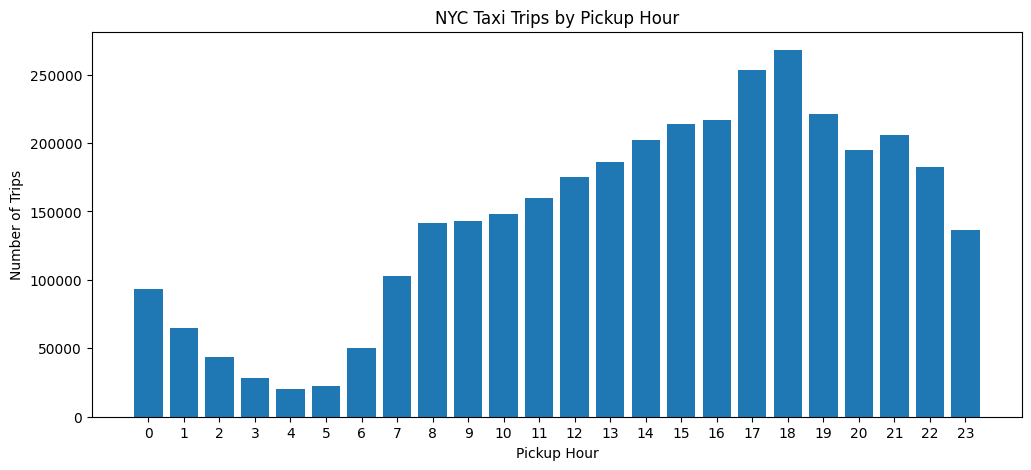

In [ ]:
plt.figure(figsize=(12,5))
plt.bar(hour_counts.index, hour_counts.values)
plt.title("NYC Taxi Trips by Pickup Hour")
plt.xlabel("Pickup Hour")
plt.ylabel("Number of Trips")
plt.xticks(range(24))
plt.show()


#Trips by Day

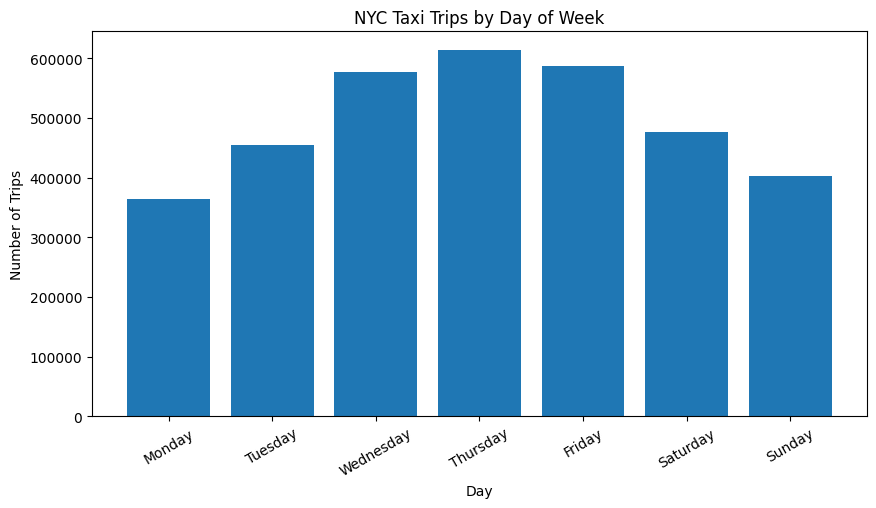

In [ ]:
plt.figure(figsize=(10,5))
plt.bar(day_counts.index, day_counts.values)
plt.title("NYC Taxi Trips by Day of Week")
plt.xlabel("Day")
plt.ylabel("Number of Trips")
plt.xticks(rotation=30)
plt.show()


#Hour × Day Heatmap

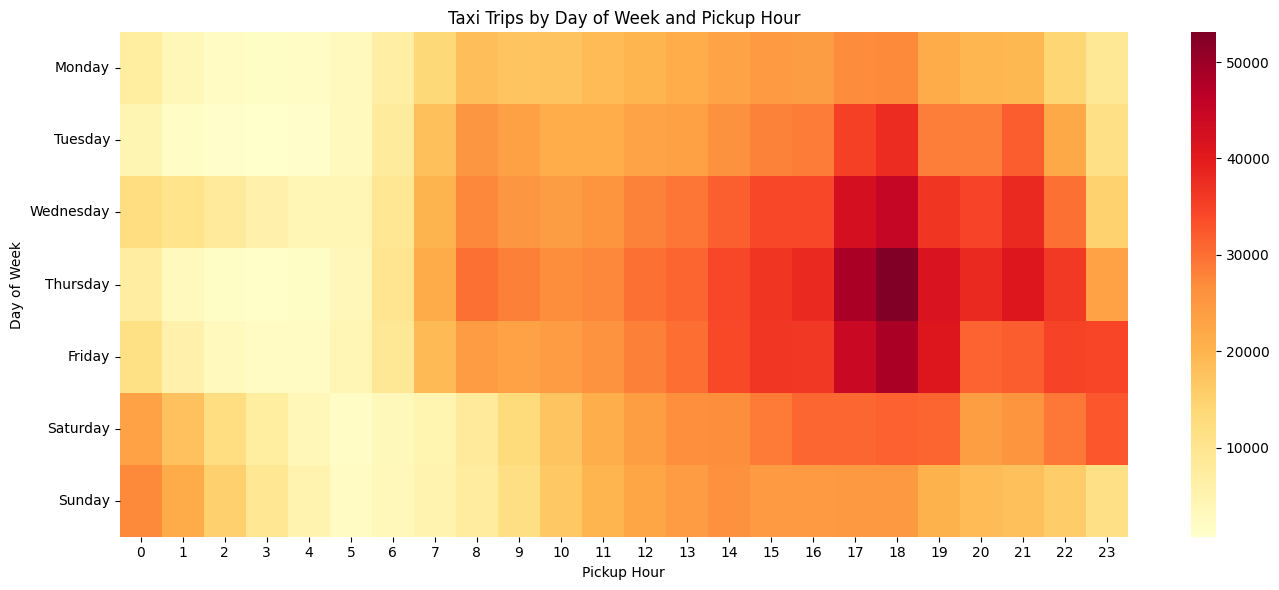

In [ ]:
hour_day=pd.crosstab(clean_df["day_of_week"],clean_df["pickup_hour"]).reindex(day_order)
plt.figure(figsize=(14,6))
sns.heatmap(hour_day, cmap="YlOrRd")
plt.title("Taxi Trips by Day of Week and Pickup Hour")
plt.xlabel("Pickup Hour")
plt.ylabel("Day of Week")
plt.tight_layout()
plt.show()



#Average Duration by Hour

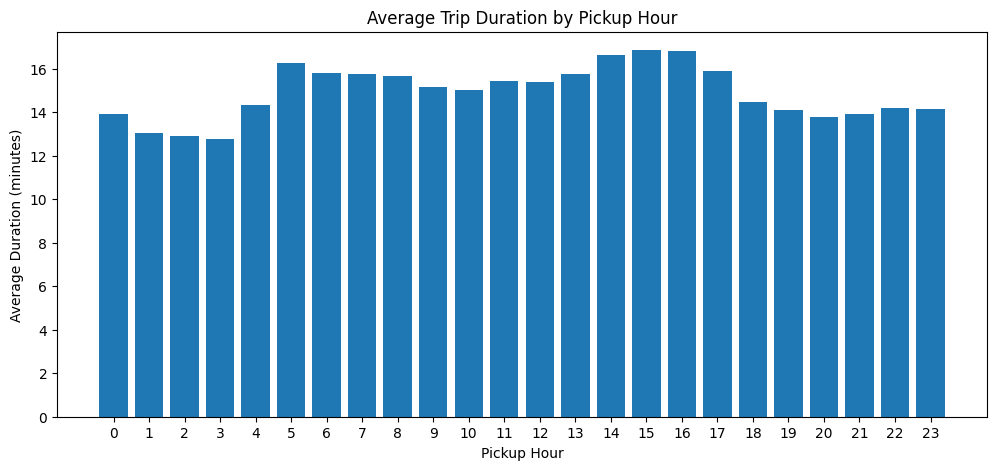

In [ ]:
duration_by_hour = analysis_df.groupby("pickup_hour")["trip_duration_minutes"].mean()
plt.figure(figsize=(12,5))
plt.bar(duration_by_hour.index, duration_by_hour.values)
plt.title("Average Trip Duration by Pickup Hour")
plt.xlabel("Pickup Hour")
plt.ylabel("Average Duration (minutes)")
plt.xticks(range(24))
plt.show()


#Average Distance by Hour

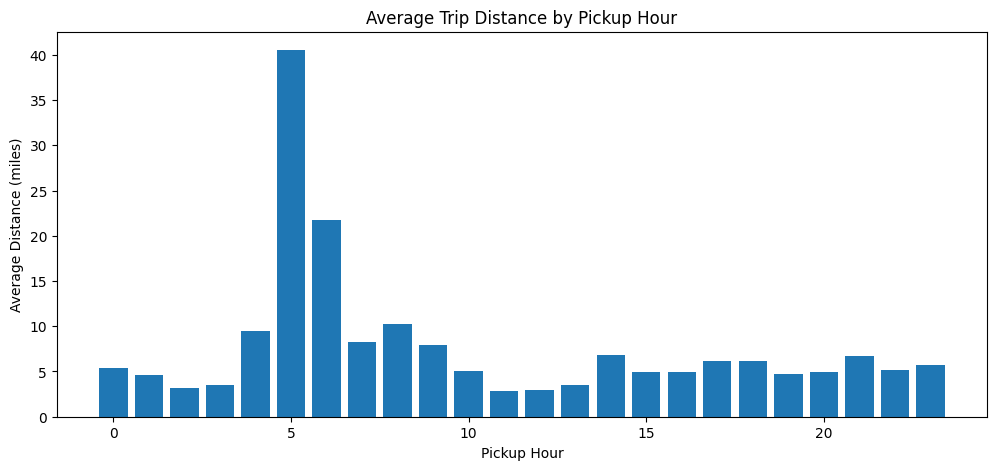

In [ ]:
distance_by_hour = analysis_df.groupby("pickup_hour")["trip_distance"].mean()
plt.figure(figsize=(12,5))
plt.bar(distance_by_hour.index, distance_by_hour.values)
plt.title("Average Trip Distance by Pickup Hour")
plt.xlabel("Pickup Hour")
plt.ylabel("Average Distance (miles)")
plt.show()


#Trip Distance & Duration Analysis

#Trip Distance Histogram

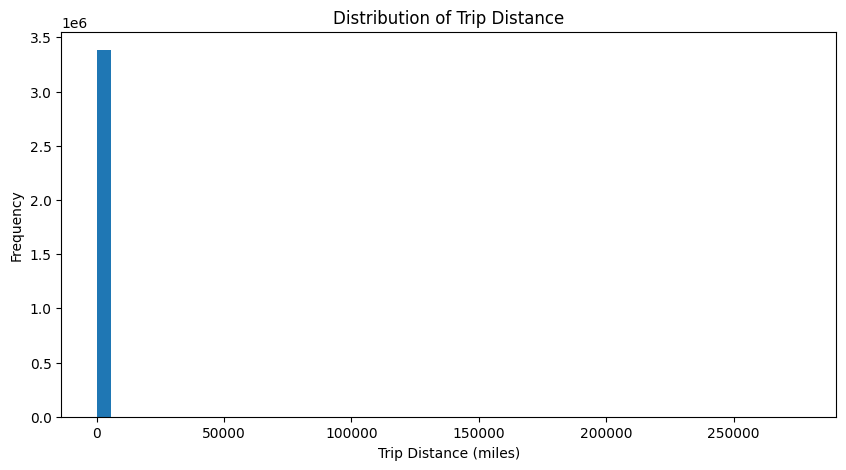

In [ ]:
plt.figure(figsize=(10,5))
plt.hist(analysis_df["trip_distance"], bins=50)
plt.title("Distribution of Trip Distance")
plt.xlabel("Trip Distance (miles)")
plt.ylabel("Frequency")
plt.show()


### Visualization 7 — Trip Duration Histogram

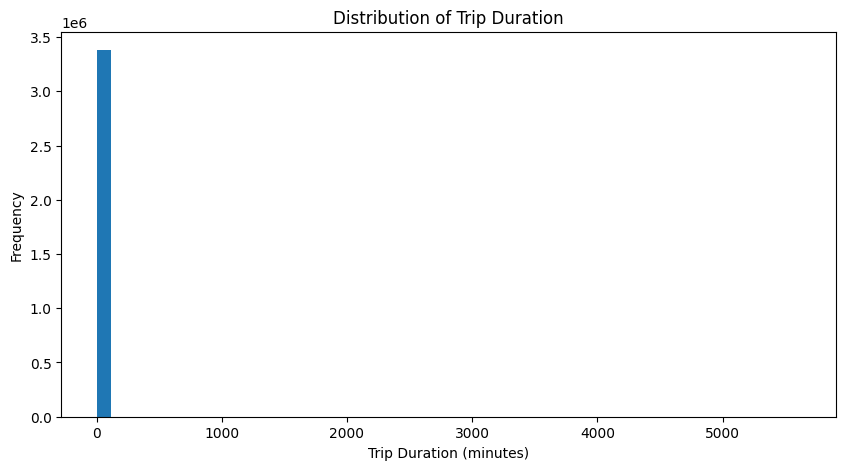

In [ ]:
plt.figure(figsize=(10,5))
plt.hist(analysis_df["trip_duration_minutes"], bins=50)
plt.title("Distribution of Trip Duration")
plt.xlabel("Trip Duration (minutes)")
plt.ylabel("Frequency")
plt.show()


#Trip Distance Boxplot

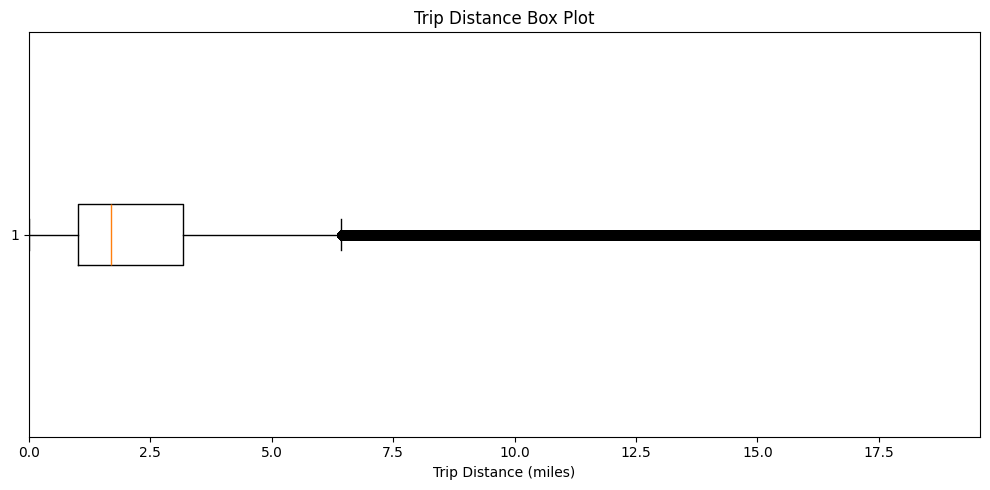

In [ ]:
plt.figure(figsize=(10,5))
plt.boxplot(analysis_df["trip_distance"].dropna(), vert=False)
plt.title("Trip Distance Box Plot")
plt.xlabel("Trip Distance (miles)")
plt.xlim(0, analysis_df["trip_distance"].quantile(0.99))
plt.tight_layout()
plt.show()


#Trip Duration Boxplot

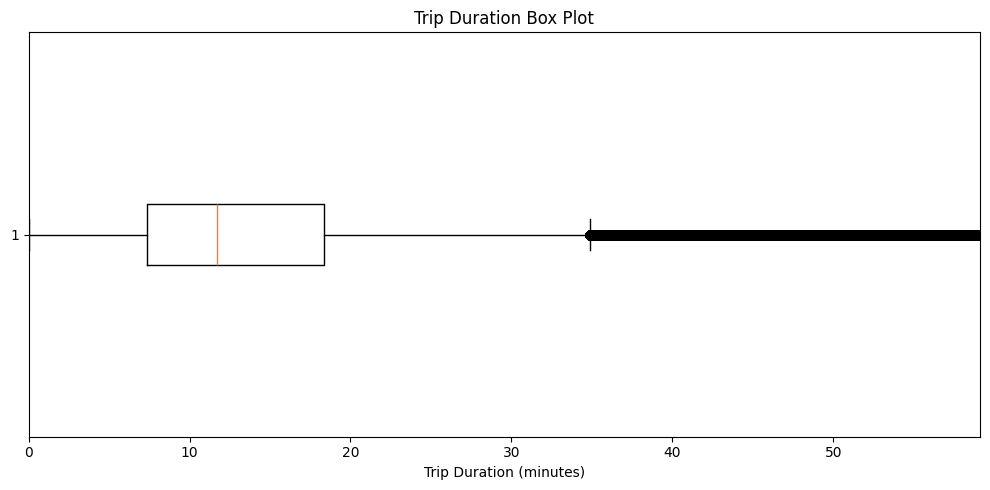

In [ ]:
plt.figure(figsize=(10,5))
plt.boxplot(analysis_df["trip_duration_minutes"].dropna(),vert=False)
plt.title("Trip Duration Box Plot")
plt.xlabel("Trip Duration (minutes)")
plt.xlim(0, analysis_df["trip_duration_minutes"].quantile(0.99))
plt.tight_layout()
plt.show()


#Distance vs Duration

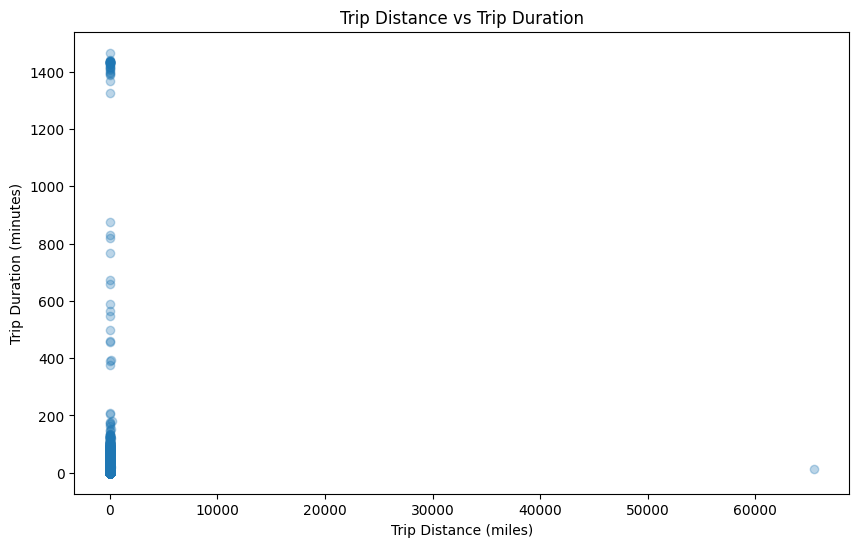

In [ ]:
sample = analysis_df.sample(min(100000, len(analysis_df)),random_state=42)
plt.figure(figsize=(10,6))
plt.scatter(sample["trip_distance"], sample["trip_duration_minutes"], alpha=0.3)
plt.title("Trip Distance vs Trip Duration")
plt.xlabel("Trip Distance (miles)")
plt.ylabel("Trip Duration (minutes)")

plt.show()


# Distance vs Average Speed

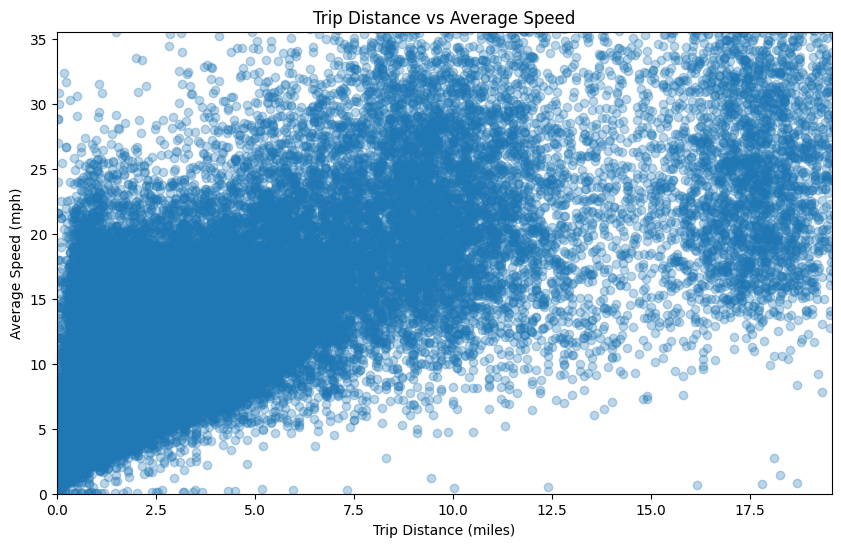

In [ ]:
plt.figure(figsize=(10,6))
plt.scatter(sample["trip_distance"],sample["average_speed_mph"],alpha=0.3)
plt.title("Trip Distance vs Average Speed")
plt.xlabel("Trip Distance (miles)")
plt.ylabel("Average Speed (mph)")
plt.xlim(0,sample["trip_distance"].quantile(0.99))
plt.ylim(0,sample["average_speed_mph"].quantile(0.99))
plt.show()


#Passenger Analysis

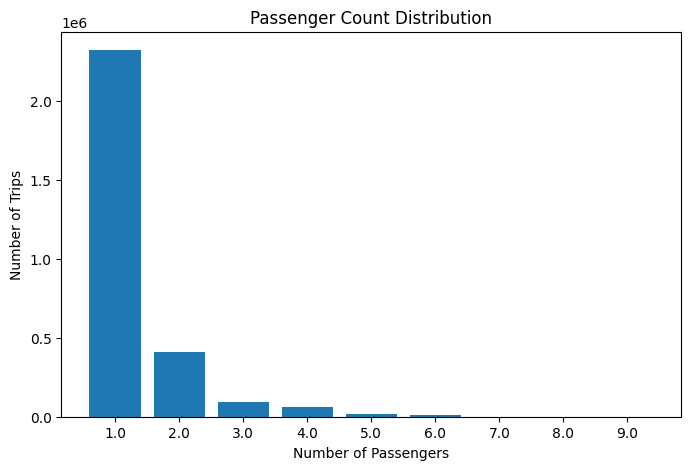

Most common passenger count: 1.0
One-passenger percentage: 66.83 %


In [ ]:
passenger_counts = clean_df["passenger_count"].value_counts().sort_index()
plt.figure(figsize=(8,5))
plt.bar(passenger_counts.index.astype(str), passenger_counts.values)
plt.title("Passenger Count Distribution")
plt.xlabel("Number of Passengers")
plt.ylabel("Number of Trips")
plt.show()

print("Most common passenger count:", clean_df["passenger_count"].mode().iloc[0])
print("One-passenger percentage:", round((clean_df["passenger_count"] == 1).mean()*100, 2), "%")


## 13. Pickup & Drop-off Location Analysis

In [ ]:
top_pickups=clean_df["PULocationID"].value_counts().head(10)
top_dropoffs=clean_df["DOLocationID"].value_counts().head(10)
print("Top pickup locations:")
display(top_pickups)
print("Top drop-off locations:")
display(top_dropoffs)


Top pickup locations:


,count
PULocationID,
161,169977
237,163702
236,155644
132,146137
230,125828
186,119131
162,117929
142,110584
239,96614


Top drop-off locations:


,count
DOLocationID,
236,161376
237,149970
161,131258
230,108177
170,100057
142,98981
239,97559
162,93798
141,92675



#Top Pickup Locations

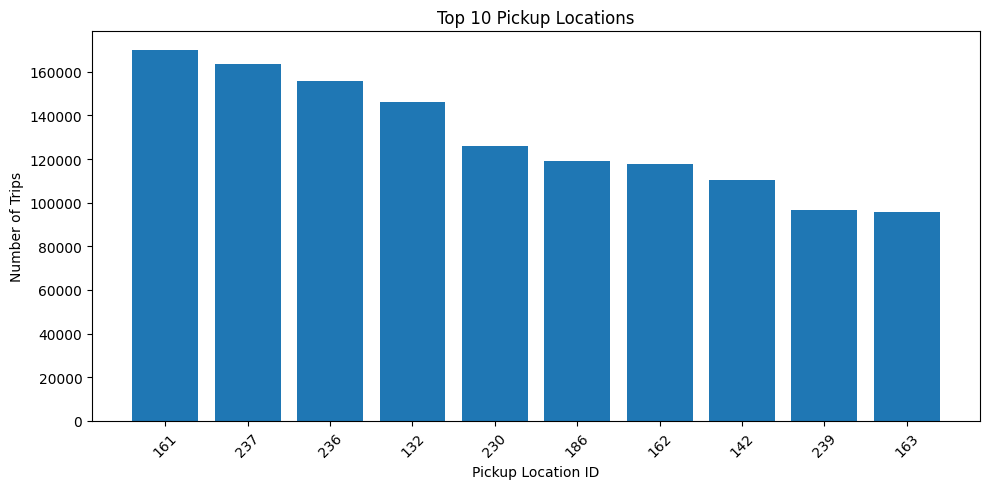

In [ ]:
plt.figure(figsize=(10,5))
plt.bar(top_pickups.index.astype(str),top_pickups.values)
plt.title("Top 10 Pickup Locations")
plt.xlabel("Pickup Location ID")
plt.ylabel("Number of Trips")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


#Top Drop-off Locations

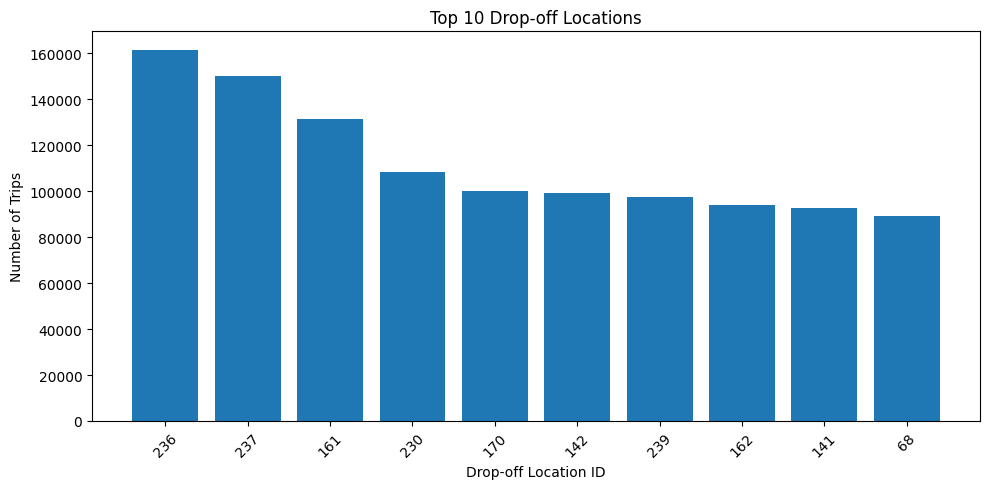

In [ ]:
plt.figure(figsize=(10,5))
plt.bar(top_dropoffs.index.astype(str),top_dropoffs.values)
plt.title("Top 10 Drop-off Locations")
plt.xlabel("Drop-off Location ID")
plt.ylabel("Number of Trips")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


#Route Analysis

In [ ]:
route_table=(clean_df.groupby(["PULocationID","DOLocationID"]).size().reset_index(name="Number_of_Trips").sort_values("Number_of_Trips", ascending=False))
display(route_table.head(20))


,PULocationID,DOLocationID,Number_of_Trips
29130,237,236,24839
28916,236,237,21843
28915,236,236,18221
29131,237,237,17441
19473,161,237,11463
29068,237,161,10168
19472,161,236,9845
29521,239,238,9595
17030,142,239,9141
29455,239,142,8844


#Payment Type Analysis

,count
payment_type,
0,540031
1,2444387
2,390429
3,23773
4,76481
5,1


,proportion
payment_type,
0,15.540004
1,70.340007
2,11.235037
3,0.684095
4,2.200827
5,0.000029


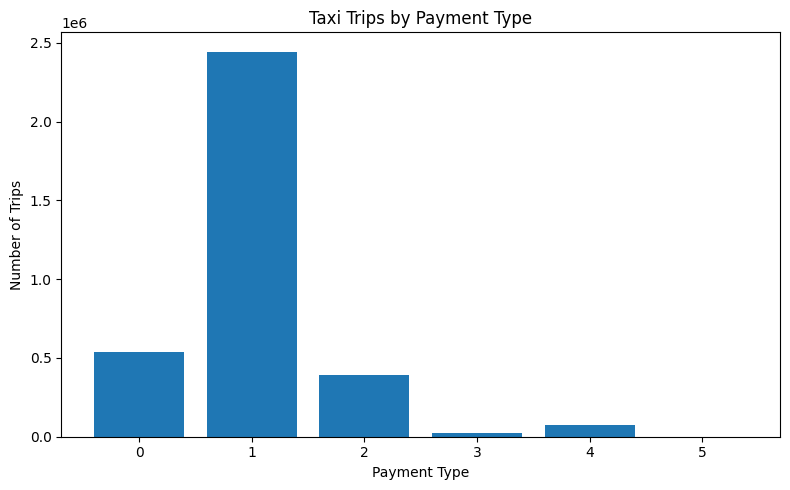

,trip_count,average_distance,average_duration,average_passengers
payment_type,,,,
0,488035,22.482147,15.327623,NaN
1,2423680,3.221951,15.079081,1.295496
2,381364,3.214565,15.333975,1.378291
3,18911,3.199282,13.666166,1.346603
4,70984,3.904165,14.767372,1.348720


In [ ]:
payment_counts = clean_df["payment_type"].value_counts().sort_index()
payment_percentage = clean_df["payment_type"].value_counts(normalize=True).sort_index() * 100

display(payment_counts)
display(payment_percentage)

plt.figure(figsize=(8,5))
plt.bar(payment_counts.index.astype(str), payment_counts.values)
plt.title("Taxi Trips by Payment Type")
plt.xlabel("Payment Type")
plt.ylabel("Number of Trips")
plt.tight_layout()
plt.show()

payment_summary = analysis_df.groupby("payment_type").agg(
    trip_count=("payment_type","size"),
    average_distance=("trip_distance","mean"),
    average_duration=("trip_duration_minutes","mean"),
    average_passengers=("passenger_count","mean")
)
display(payment_summary)


## 16. Vendor Analysis

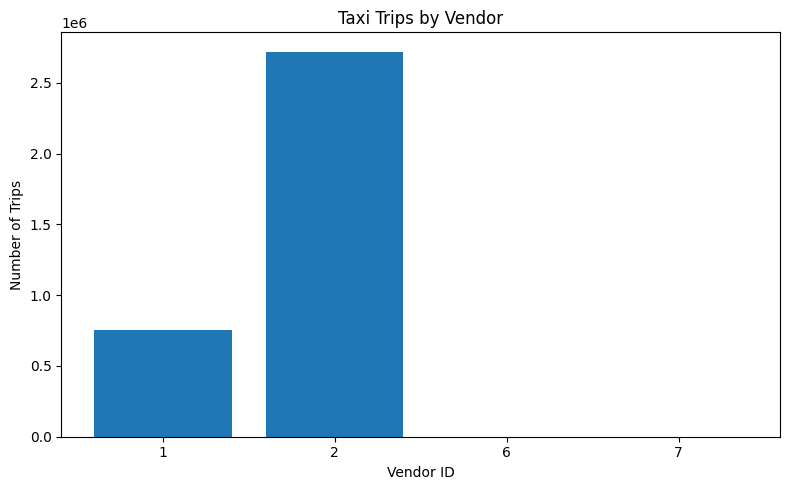

,trip_count,average_distance,average_duration,average_passengers,percentage
VendorID,,,,,
1,738035,3.265724,15.799163,1.186587,21.816159
2,2644573,6.780265,14.938562,1.342083,78.173022
6,366,9.520847,41.925774,NaN,0.010819


In [ ]:
vendor_counts=clean_df["VendorID"].value_counts().sort_index()
plt.figure(figsize=(8,5))
plt.bar(vendor_counts.index.astype(str),vendor_counts.values)
plt.title("Taxi Trips by Vendor")
plt.xlabel("Vendor ID")
plt.ylabel("Number of Trips")
plt.tight_layout()
plt.show()

vendor_summary=analysis_df.groupby("VendorID").agg(trip_count=("VendorID","size"),average_distance=("trip_distance","mean"),average_duration=("trip_duration_minutes","mean"),
    average_passengers=("passenger_count","mean"))
vendor_summary["percentage"]=vendor_summary["trip_count"] / vendor_summary["trip_count"].sum() * 100
display(vendor_summary)


## 17. Rate Code Analysis

,count
RatecodeID,
1.0,2756471
2.0,94420
3.0,8622
4.0,7092
5.0,26501
6.0,7
99.0,41958


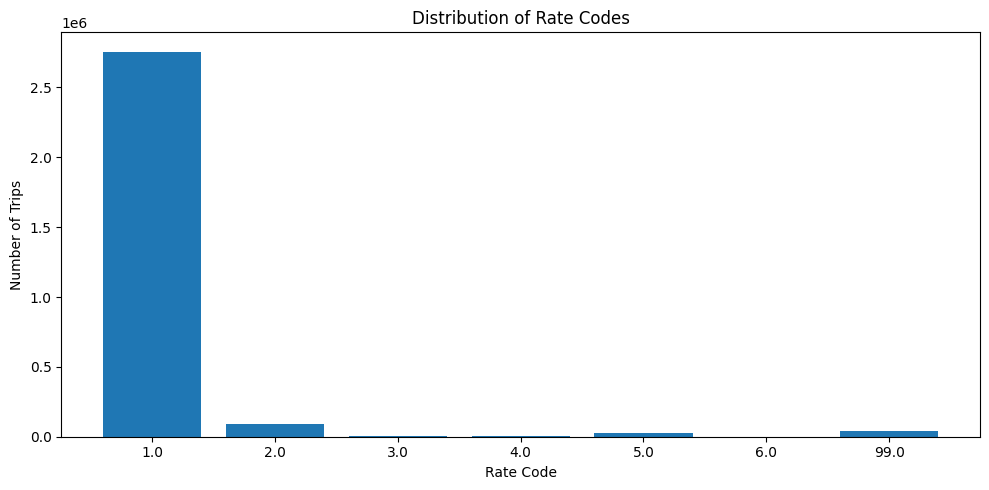

,trip_count,average_distance,average_duration,percentage
RatecodeID,,,,
1.0,2733503,2.516015,13.466505,94.423509
2.0,91422,17.741928,45.263038,3.157994
3.0,8037,15.392335,32.387205,0.277622
4.0,7074,21.015185,40.396958,0.244357
5.0,15808,9.318097,24.571306,0.546056
6.0,7,0.457143,0.733333,0.000242
99.0,39088,11.597465,46.513486,1.350218


In [ ]:
rate_counts = clean_df["RatecodeID"].value_counts().sort_index()
display(rate_counts)

plt.figure(figsize=(10,5))
plt.bar(rate_counts.index.astype(str), rate_counts.values)
plt.title("Distribution of Rate Codes")
plt.xlabel("Rate Code")
plt.ylabel("Number of Trips")
plt.tight_layout()
plt.show()

rate_summary = analysis_df.groupby("RatecodeID").agg(trip_count=("RatecodeID","size"),average_distance=("trip_distance","mean"),average_duration=("trip_duration_minutes","mean"))
rate_summary["percentage"] = rate_summary["trip_count"] / rate_summary["trip_count"].sum() * 100
display(rate_summary)


#Store & Forward Analysis

In [ ]:
store_summary=analysis_df.groupby("store_and_fwd_flag").agg(trip_count=("store_and_fwd_flag","size"),average_distance=("trip_distance","mean"),average_duration=("trip_duration_minutes","mean"))
store_summary["percentage"]=store_summary["trip_count"]/store_summary["trip_count"].sum()*100
display(store_summary)


,trip_count,average_distance,average_duration,percentage
store_and_fwd_flag,,,,
N,2887750,3.238649,15.099076,99.75167
Y,7189,2.799388,13.774160,0.24833


#Correlation Analysis



,passenger_count,trip_distance,trip_duration_minutes,average_speed_mph
passenger_count,1.000000,0.003504,0.023926,0.001160
trip_distance,0.003504,1.000000,0.003020,0.785067
trip_duration_minutes,0.023926,0.003020,1.000000,-0.000366
average_speed_mph,0.001160,0.785067,-0.000366,1.000000


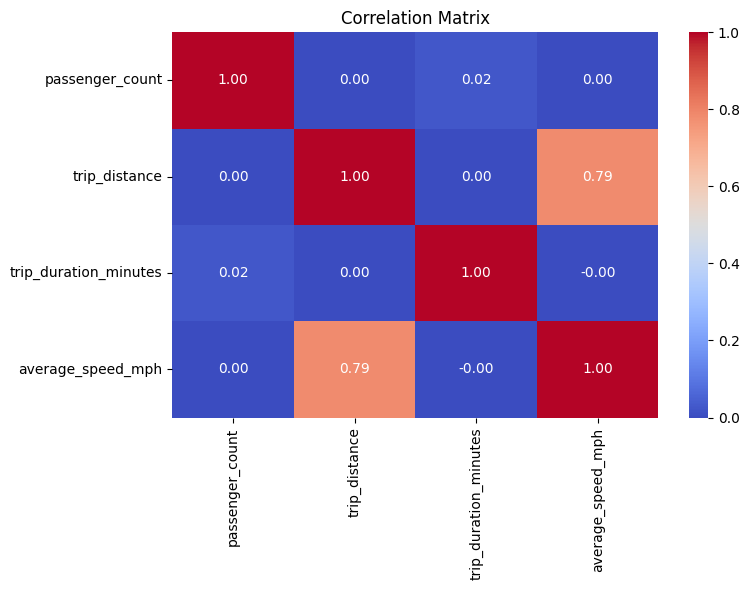

In [ ]:
corr=analysis_df[["passenger_count","trip_distance","trip_duration_minutes","average_speed_mph"]].corr()
display(corr)
plt.figure(figsize=(8,6))
sns.heatmap(corr,annot=True,cmap="coolwarm",fmt=".2f")
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()


**Interpretation:** Correlation indicates association between numerical variables; it does not establish causation.

#weekday vs Weekend

In [ ]:
weekend_summary = clean_df.groupby("is_weekend").agg(trips=("is_weekend","size"),average_distance=("trip_distance","mean"),average_duration=("trip_duration_minutes","mean"),
    average_speed=("average_speed_mph","mean"))
display(weekend_summary)


,trips,average_distance,average_duration,average_speed
is_weekend,,,,
False,2596123,5.903726,15.369902,25.794830
True,878979,5.711517,14.040050,25.560401


#Final KPI Summary

In [ ]:
kpis={"Total Trips": len(clean_df),"Average Trip Distance":analysis_df["trip_distance"].mean(),"Median Trip Distance":analysis_df["trip_distance"].median(),
    "Average Trip Duration":analysis_df["trip_duration_minutes"].mean(),"Median Trip Duration":analysis_df["trip_duration_minutes"].median(),
    "Maximum Trip Distance":analysis_df["trip_distance"].max(),"Maximum Trip Duration":analysis_df["trip_duration_minutes"].max(),"Average Speed": analysis_df["average_speed_mph"].mean(),
    "Most Common Passenger Count": clean_df["passenger_count"].mode().iloc[0],"Busiest Pickup Hour": clean_df["pickup_hour"].value_counts().idxmax(),
    "Busiest Day": clean_df["day_of_week"].value_counts().idxmax(),"Most Common Payment Type": clean_df["payment_type"].mode().iloc[0],"Most Common Pickup Location": clean_df["PULocationID"].mode().iloc[0],
    "Most Common Drop-off Location": clean_df["DOLocationID"].mode().iloc[0],"Most Common Route": clean_df["route"].mode().iloc[0]}
display(pd.DataFrame(list(kpis.items()), columns=["KPI","Value"]))


,KPI,Value
0,Total Trips,3475102
1,Average Trip Distance,6.013823
2,Median Trip Distance,1.7
3,Average Trip Duration,15.129231
4,Median Trip Duration,11.733333
5,Maximum Trip Distance,276423.57
6,Maximum Trip Duration,5626.316667
7,Average Speed,26.421719
8,Most Common Passenger Count,1.0
9,Busiest Pickup Hour,18


#Limitations


1. The dataset covers only January 2025, so the results may not represent other months or years.


2. PULocationID and DOLocationID are Taxi Zone IDs, not direct neighborhood names.


3. The dataset does not contain fare, tip, revenue, profit, customer ID, or driver ID, so financial and customer-level analysis cannot be performed.


4. Missing values and unusual/outlier records may affect some statistical results.


5. Correlation shows association, not causation, so causal conclusions cannot be made from the analysis alone.

#conclusion
1. The NYC Yellow Taxi data was successfully cleaned, analyzed and transformed using Python.

2. Trip duration, distance, speed, passenger and time-based patterns were identified through statistical analysis.

3. Taxi demand patterns were analyzed across different hours, days, pickup/drop-off locations and routes.

4. Payment types, vendors, rate codes and store-and-forward trips were compared to understand operational patterns.

5. Overall, the analysis provides useful data-driven insights into NYC taxi operations, while recognizing the dataset's limitations.